# Практичне завдання 3: Дослідження ефективності TF-IDF зважених ембедингів для детекції текстів, згенерованих LLM

**Виконала:** Зімірська Юліана, група ФЕІ-42

**Датасет:** AI vs Human Text Classification Dataset 2026 (Kaggle), файл `ai_vs_human_text_2026.csv`

**Мета:** побудувати документні вектори з субсловних ембедингів FastText, дослідити вплив TF-IDF зважування
на агрегацію (Mean Pooling vs TF-IDF Weighted Mean), порівняти SVM (RBF), Logistic Regression та KNN
у бінарній детекції AI-текстів і проаналізувати геометрію отриманих векторних просторів.

---

### Структура роботи

| Етап | Зміст |
|---|---|
| 1 | Завантаження, первинний аналіз, артефакти даних (дублікати, витік через метадані, шаблони) |
| 2 | Препроцесинг spaCy (`nlp.pipe` з батчами), дедуплікація після нормалізації, розбиття |
| 3 | Навчання FastText (gensim) лише на train |
| 4 | Mean Pooling та TF-IDF Weighted Mean |
| 5 | SVM / LogReg / KNN: основний протокол + додаткові експерименти (крива навчання, нові шаблони) |
| 6 | t-SNE, UMAP, матриці плутанини, геометричні метрики, лінгвістичний аналіз |
| — | Відповіді на 5 дослідницьких питань і висновки |

### Принцип запобігання витоку даних

Усе, що «навчається» на даних, — словник і ваги FastText, IDF-статистика, параметри StandardScaler —
обчислюється **лише на train-частині** відповідного розбиття. У крос-валідації за шаблонами FastText та IDF
перенавчаються на кожному фолді.

In [1]:
import re, time, warnings, zlib
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from gensim.models import FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     StratifiedGroupKFold, cross_validate)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix, silhouette_score)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import umap

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
def stable_hash(s):
    # детермінований хеш замість вбудованого hash(), який рандомізується між запусками Python
    return zlib.crc32(s.encode('utf-8'))

COL = {'human': '#3B6FB6', 'ai': '#D9643A'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3})

---
# Етап 1. Завантаження та первинний аналіз даних

In [2]:
raw = pd.read_csv('ai_vs_human_text_2026.csv')
print('Розмір:', raw.shape)
raw.info()
raw.head()

Розмір: (2000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   str    
 1   label                2000 non-null   str    
 2   source_model         2000 non-null   str    
 3   domain               2000 non-null   str    
 4   text_content         2000 non-null   str    
 5   topic_hint           2000 non-null   str    
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 140.8 KB


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


In [3]:
print('Пропуски:\n', raw.isna().sum().to_string())
print('\nПорожні / пробільні тексти:', (raw.text_content.str.strip() == '').sum())
print('\nБаланс класів:')
print(raw.label.value_counts().to_frame('n').assign(share=lambda t: (t.n / t.n.sum()).round(3)))

Пропуски:
 text_id                0
label                  0
source_model           0
domain                 0
text_content           0
topic_hint             0
word_count             0
avg_sentence_length    0
generation_method      0

Порожні / пробільні тексти: 0

Баланс класів:
          n  share
label             
human  1334  0.667
ai      666  0.333


Пропусків і порожніх текстів немає. Класи **незбалансовані 2:1** (1334 human / 666 AI), тому поряд
з Accuracy обов'язково дивимось на F1 macro та Balanced Accuracy, а розбиття робимо стратифікованим.

In [4]:
for c in ['source_model', 'generation_method', 'domain']:
    print(pd.crosstab(raw[c], raw.label), '\n')

label          ai  human
source_model            
gemini-2.0    333      0
gpt-4o        333      0
human           0   1334 

label                      ai  human
generation_method                   
style_simulation          666      0
template+human_variation    0   1334 

label      ai  human
domain              
academic  222    447
news      222    435
social    222    452 



**Витік через метадані.** Колонки `source_model` (`human` / `gpt-4o` / `gemini-2.0`) та `generation_method`
(`template+human_variation` / `style_simulation`) **однозначно визначають мітку**. Класифікатор, який їх бачить,
отримає 100 % без жодного аналізу тексту. Тому в моделях використовується **тільки `text_content`**.
`domain` розподілений між класами рівномірно (по 222 AI-тексти на домен) і сам по собі мітку не видає.

In [5]:
n_unique = raw.text_content.nunique()
dup_mask = raw.duplicated('text_content', keep='first')
conflict = raw.groupby('text_content').label.nunique().gt(1).sum()
print(f'Унікальних текстів: {n_unique} із {len(raw)}')
print(f'Рядків-дублікатів (повторні копії): {dup_mask.sum()}')
print(f'Текстів, що мають конфліктні мітки: {conflict}')
print('\nМаксимальна кількість копій одного тексту:', raw.text_content.value_counts().max())
print('\nПісля видалення дублікатів:')
print(raw.drop_duplicates('text_content').label.value_counts())

Унікальних текстів: 966 із 2000
Рядків-дублікатів (повторні копії): 1034
Текстів, що мають конфліктні мітки: 0

Максимальна кількість копій одного тексту: 11

Після видалення дублікатів:
label
human    579
ai       387
Name: count, dtype: int64


**Дублікати — головний артефакт датасету.** Лише 966 із 2000 рядків унікальні; окремі тексти повторюються
до 11 разів. Конфліктних міток немає. Якщо залишити дублікати, одна й та сама копія з великою ймовірністю
потрапить і в train, і в test — оцінка на тесті перетвориться на перевірку запам'ятовування.
Тому дублікати видаляються **до** розбиття. Після цього баланс стає 579 / 387 (≈ 60 / 40).

In [6]:
raw['n_words'] = raw.text_content.str.split().str.len()
raw['n_chars'] = raw.text_content.str.len()
print('Збіг n_words з word_count:', (raw.n_words == raw.word_count).mean().round(3))
print(raw.groupby('label')[['n_words', 'n_chars', 'avg_sentence_length']].describe().T.round(1))
print('\nТекстів коротших за 10 слів:', (raw.n_words < 10).sum())

Збіг n_words з word_count: 1.0
label                         ai   human
n_words             count  666.0  1334.0
                    mean    38.0    36.5
                    std      7.0     9.7
                    min     23.0    19.0
                    25%     35.0    27.0
                    50%     39.0    36.0
                    75%     44.0    46.0
                    max     50.0    52.0
n_chars             count  666.0  1334.0
                    mean   275.6   252.7
                    std     71.1    88.3
                    min    152.0   123.0
                    25%    204.0   153.0
                    50%    295.0   253.0
                    75%    334.0   330.0
                    max    385.0   398.0
avg_sentence_length count  666.0  1334.0
                    mean    13.3    12.5
                    std      2.3     3.1
                    min      8.7     6.5
                    25%     12.0    10.0
                    50%     13.0    13.0
                    75%   

Тексти короткі й однорідні за довжиною: 19–52 слова, у середньому 38 (AI) і 36.5 (human).
Надмірно коротких текстів (< 10 слів) немає, тож відкидати нічого не потрібно. Довжина слабо розрізняє класи:
розподіли сильно перекриваються, у людського класу лише трохи ширший розкид (std 9.7 проти 7.0).

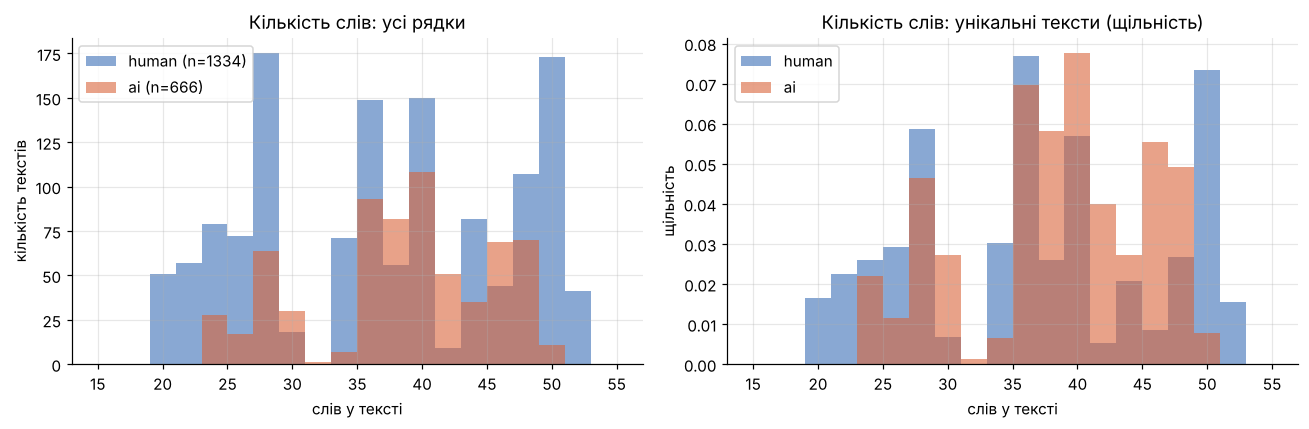

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(15, 56, 2)
for lab in ['human', 'ai']:
    s = raw[raw.label == lab]
    ax[0].hist(s.n_words, bins=bins, alpha=.6, color=COL[lab], label=f'{lab} (n={len(s)})')
    u = raw.drop_duplicates('text_content')
    ax[1].hist(u[u.label == lab].n_words, bins=bins, alpha=.6, color=COL[lab], label=lab, density=True)
ax[0].set(title='Кількість слів: усі рядки', xlabel='слів у тексті', ylabel='кількість текстів')
ax[1].set(title='Кількість слів: унікальні тексти (щільність)', xlabel='слів у тексті', ylabel='щільність')
for a in ax: a.legend()
plt.tight_layout(); plt.show()

### Шаблонна природа датасету

Перегляд прикладів показує, що тексти побудовані з **фіксованих шаблонів**, у які підставлено тему
(`topic_hint`). Наприклад, усі тексти виду «This paper examines *X* through a critical lens…» відрізняються лише *X*.
Виділимо шаблон, замінивши тему на `<T>` (і назви днів тижня — на `<day>`), та порахуємо, скільки їх.

In [8]:
def to_template(text, topic):
    s = re.sub(re.escape(topic), '<T>', text, flags=re.I).lower()
    s = re.sub(r'monday|tuesday|wednesday|thursday|friday|saturday|sunday', '<day>', s)
    return re.sub(r'\s+', ' ', s).strip()

df = raw.drop_duplicates('text_content').reset_index(drop=True).copy()
df['template'] = [to_template(t, h) for t, h in zip(df.text_content, df.topic_hint)]
df['tpl_id'] = df.template.astype('category').cat.codes
print('Унікальних текстів:', len(df))
print('Унікальних шаблонів:', df.template.nunique(), df.groupby('label').template.nunique().to_dict())
print('Шаблонів, спільних для обох класів:', (df.groupby('template').label.nunique() > 1).sum())
print('Тем (topic_hint):', df.topic_hint.nunique())
for lab in ['ai', 'human']:
    print(f'\n--- Приклади шаблонів класу {lab} ---')
    for t in df[df.label == lab].template.value_counts().index[:3]:
        print('•', t[:160], '...')

Унікальних текстів: 966
Унікальних шаблонів: 34 {'ai': 18, 'human': 16}
Шаблонів, спільних для обох класів: 0
Тем (topic_hint): 30

--- Приклади шаблонів класу ai ---
• i've been thinking a lot about <t> lately, and i think we need to have a more nuanced conversation about it. the polarization isn't helping anyone. happy to dis ...
• the concept of <t> occupies a contested space within contemporary scholarly discourse. divergent theoretical frameworks have produced inconsistent empirical fin ...
• new developments surrounding <t> have drawn significant attention from analysts and policymakers alike. experts suggest the implications could be far-reaching,  ...

--- Приклади шаблонів класу human ---
• officials confirmed on <day> that <t>. the announcement came after weeks of speculation. critics argue the move is premature, while supporters say it was long o ...
• the relationship between <t> and broader societal outcomes remains poorly understood despite growing interest in the field. 

Увесь корпус зводиться до **34 шаблонів** (18 AI, 16 human) × 30 тем, причому **жоден шаблон не трапляється
в обох класах**. Отже, задача «AI чи людина» на цьому датасеті еквівалентна задачі «який це шаблон»:
модель, що впізнає шаблон, автоматично знає клас. Це критично для інтерпретації метрик (див. Етап 5).

In [9]:
# Стильові артефакти людського класу, які зникнуть після препроцесингу
art = pd.DataFrame({
    'подвійний пробіл': df.text_content.str.contains('  '),
    'починається з малої літери': df.text_content.str.match(r'^[a-z]'),
    '"??" або "!!"': df.text_content.str.contains(r'\?\?|!!'),
    'слово капсом (>=4 літер)': df.text_content.str.contains(r'\b[A-Z]{4,}\b'),
}).groupby(df.label).mean().T.round(3)
art

label,ai,human
подвійний пробіл,0.0,0.176
починається з малої літери,0.0,0.371
"""??"" або ""!!""",0.0,0.092
слово капсом (>=4 літер),0.0,0.045


«Людська варіативність» (`template+human_variation`) полягає у поверхневих спотвореннях: подвійних пробілах,
малих літерах на початку, «??», словах капсом. В AI-текстах таких артефактів немає зовсім.
Це сильний сигнал, але **пайплайн із завдання його повністю знищує**: зведення до нижнього регістру,
`is_alpha` та видалення стоп-слів прибирають і регістр, і пунктуацію, і пробіли.
Тобто модель на ембедингах цього «чесного» стильового сигналу не бачить — лише лексику.

---
# Етап 2. Попередня обробка тексту (spaCy)

Пайплайн відповідає вимогам завдання: лематизація (`lemma_`), видалення стоп-слів (`is_stop`),
лише буквені токени (`is_alpha`), нижній регістр. Для швидкості використано `nlp.pipe(batch_size=256)`
і вимкнено непотрібні компоненти `parser` та `ner` (лематизатору потрібні лише `tagger`/`attribute_ruler`).

In [10]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

def preprocess_corpus(texts, batch_size=256):
    out = []
    for doc in nlp.pipe(texts, batch_size=batch_size):
        out.append([tok.lemma_.lower() for tok in doc if tok.is_alpha and not tok.is_stop])
    return out

t0 = time.time()
df['tokens'] = preprocess_corpus(df.text_content.tolist())
print(f'Оброблено {len(df)} текстів за {time.time() - t0:.1f} с')
df['n_tokens'] = df.tokens.str.len()
print(df.groupby('label').n_tokens.describe().round(1))
for i in [0, 3]:
    print('\nОРИГІНАЛ:', df.text_content[i][:200])
    print('ТОКЕНИ  :', df.tokens[i][:25])

Оброблено 966 текстів за 1.9 с
       count  mean  std   min   25%   50%   75%   max
label                                                
ai     387.0  23.2  7.6  10.0  15.0  26.0  30.0  33.0
human  579.0  21.2  7.5   7.0  13.0  22.0  28.0  33.0

ОРИГІНАЛ: can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize
ТОКЕНИ  : ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']

ОРИГІНАЛ: This paper examines genomic research breakthroughs through a critical lens,  drawing on empirical evidence gathered over a two-year period. The findings suggest that existing frameworks are insufficie
ТОКЕНИ  : ['paper', 'examine', 'genomic', 'research', 'breakthrough', 'critical', 'lens', 'draw', 'empirical', 'evidence', 'gather', 'year', 'period', 'finding', 'suggest', 'exist', 'framework', 'insufficient', 'explain', 'observed', 'phenomenon', 'propose'

In [11]:
# Дублікати ПІСЛЯ нормалізації: тексти, що відрізнялися лише регістром / пробілами
df['tok_key'] = df.tokens.str.join(' ')
n_before = len(df)
print('Груп однакових токен-послідовностей з різними мітками:',
      (df.groupby('tok_key').label.nunique() > 1).sum())
df = df.drop_duplicates('tok_key').reset_index(drop=True)
print(f'Видалено {n_before - len(df)} текстів-дублікатів після препроцесингу, залишилось {len(df)}')
print(df.label.value_counts().to_string())

Груп однакових токен-послідовностей з різними мітками: 0
Видалено 98 текстів-дублікатів після препроцесингу, залишилось 868
label
human    481
ai       387


Після нормалізації ще **98 текстів збіглися** з іншими: вони відрізнялися лише подвійним пробілом чи регістром,
тобто тими самими людськими «варіаціями». Для моделі такі тексти ідентичні (однакові токени → однакові вектори),
тому вони теж прибрані — інакше в test потрапили б точні копії train-векторів.
Підсумковий корпус: **868 документів** (481 human / 387 AI).

Далі — стратифіковане розбиття 80/20 з `random_state=42`, як у завданні.

In [12]:
y = (df.label == 'ai').astype(int).values
idx = np.arange(len(df))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
y_train, y_test = y[tr_idx], y[te_idx]
print(f'Train: {len(tr_idx)}  Test: {len(te_idx)}')
print('Частка AI: train %.3f, test %.3f' % (y_train.mean(), y_test.mean()))
print('Шаблонів тесту, що присутні в train:',
      f"{df.template[te_idx].isin(set(df.template[tr_idx])).mean():.0%}")

Train: 694  Test: 174
Частка AI: train 0.445, test 0.448
Шаблонів тесту, що присутні в train: 100%


Частки класів у train і test однакові (≈ 0.45 AI). Але **100 % шаблонів тесту присутні в train** —
при випадковому розбитті тест перевіряє впізнавання вже бачених шаблонів з новими темами.

---
# Етап 3. Навчання FastText

Параметри — точно як у завданні (`vector_size=100, window=5, min_count=2, sg=1, seed=42`), навчання лише на train.
Дві технічні зміни заради відтворюваності:

* `workers=1` — при кількох потоках порядок оновлень ваг недетермінований, і результати відрізняються між запусками
  навіть із фіксованим `seed`;
* `hashfxn=stable_hash` (CRC32) — gensim ініціалізує вектори через вбудований `hash()`, який Python
  рандомізує в кожному процесі. Без цього кожен перезапуск ноутбука давав інші числа.

In [13]:
corpus_train = df.tokens[tr_idx].tolist()
ft = FastText(sentences=corpus_train, vector_size=100, window=5, min_count=2,
              sg=1, workers=1, seed=SEED, hashfxn=stable_hash)
vocab_all = set(t for doc in df.tokens for t in doc)
vocab_tr = set(t for doc in corpus_train for t in doc)
print('Словник моделі (min_count=2):', len(ft.wv.index_to_key))
print('Унікальних лем у train / у всьому корпусі:', len(vocab_tr), '/', len(vocab_all))
print('Лем тесту, яких немає у словнику:', len(vocab_all - set(ft.wv.index_to_key)))
print('"неіснуюче_слово" in ft.wv ->', 'qwertyfication' in ft.wv, '(OOV-вектор із n-грам)')
for w in ['study', 'researcher', 'honestly']:
    if w in ft.wv.key_to_index:
        print(f'{w:>10}:', [(s, round(c, 2)) for s, c in ft.wv.most_similar(w, topn=5)])

Словник моделі (min_count=2): 508
Унікальних лем у train / у всьому корпусі: 510 / 510
Лем тесту, яких немає у словнику: 2
"неіснуюче_слово" in ft.wv -> True (OOV-вектор із n-грам)
     study: [('analyze', 0.96), ('analysis', 0.94), ('dataset', 0.94), ('cite', 0.93), ('analyst', 0.92)]
researcher: [('research', 0.98), ('unexpected', 0.93), ('community', 0.93), ('collaborate', 0.92), ('meet', 0.92)]
  honestly: [('thread', 0.98), ('threat', 0.97), ('thoughtfully', 0.96), ('like', 0.95), ('rn', 0.95)]


Словник крихітний — **508 лем** (весь корпус містить лише 510 унікальних лем), що знову відображає шаблонність.
Перевірка `'qwertyfication' in ft.wv` повертає `True`: для FastText умова `t in model.wv` у функціях пулінгу
виконується для **будь-якого** слова, бо OOV-вектор складається з n-грам (формула 2).

Найближчі сусіди показують, що модель вивчила не загальну семантику, а **спільну появу в шаблонах**:
`researcher` ↔ `unexpected`, `collaborate`, `community` — це слова одного шаблону
(«Researchers from several universities collaborated… *unexpected but compelling*»).
`honestly` ↔ `thread`, `rn`, `like` — лексика соцмережевих людських шаблонів.

---
# Етап 4. Векторизація документів

Функції `mean_pooling` і `tfidf_weighted_pooling` — дослівно з завдання (формули 5 і 6).
TF-IDF рахується `TfidfVectorizer` з `analyzer=lambda x: x`, щоб використати вже лематизовані токени spaCy
без повторної токенізації. IDF навчається на train.

Зауваження: sklearn рахує `idf = ln((1+|D|)/(1+df)) + 1` (зі згладжуванням і доданком «+1»), що трохи відрізняється
від формули (4). Вплив цієї різниці перевірено окремо в кінці ноутбука.

In [14]:
def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    weights /= weights.sum()
    return np.average(vectors, axis=0, weights=weights)

def build_features(tokens, train_idx, model=None, return_tfidf=False):
    """FastText та IDF навчаються ЛИШЕ на train; вектори будуються для всіх документів."""
    corpus_tr = [tokens[i] for i in train_idx]
    if model is None:
        model = FastText(sentences=corpus_tr, vector_size=100, window=5, min_count=2,
                         sg=1, workers=1, seed=SEED, hashfxn=stable_hash)
    tfidf = TfidfVectorizer(analyzer=lambda x: x)   # токени вже підготовлені spaCy
    tfidf.fit(corpus_tr)
    M = tfidf.transform(tokens)
    names = tfidf.get_feature_names_out()
    X_mean = np.vstack([mean_pooling(t, model) for t in tokens])
    X_tfidf = np.vstack([
        tfidf_weighted_pooling(t, model, dict(zip(names[M[i].indices], M[i].data)))
        for i, t in enumerate(tokens)])
    return (X_mean, X_tfidf, tfidf, M) if return_tfidf else (X_mean, X_tfidf)

tokens = df.tokens.tolist()
X_mean, X_tfidf, tfidf, M_tfidf = build_features(tokens, tr_idx, model=ft, return_tfidf=True)
X = {'Mean Pooling': X_mean, 'TF-IDF Weighted': X_tfidf}
print('Форма матриць:', X_mean.shape, X_tfidf.shape)
print('Нульових векторів:', (np.abs(X_mean).sum(1) == 0).sum(), (np.abs(X_tfidf).sum(1) == 0).sum())

# приклад ваг для одного документа
i = te_idx[0]
names = tfidf.get_feature_names_out()
w = pd.Series(dict(zip(names[M_tfidf[i].indices], M_tfidf[i].data))).sort_values(ascending=False)
print('\nДокумент:', df.text_content[i][:150], '...\nКлас:', df.label[i])
print(f'Нормовані ваги TF-IDF (рівна вага Mean Pooling = 1/{len(w)} = {1/len(w):.3f}):')
print((w / w.sum()).round(3).to_string())

Форма матриць: (868, 100) (868, 100)
Нульових векторів: 0 0

Документ: update on algorithmic bias in hiring: it's complicated and anyone telling you otherwise is selling something. do your own research please ...
Клас: human
Нормовані ваги TF-IDF (рівна вага Mean Pooling = 1/8 = 0.125):
hiring         0.165
complicated    0.135
update         0.135
sell           0.135
algorithmic    0.118
bias           0.118
tell           0.108
research       0.086


Навіть на прикладі видно ключову властивість: нормовані TF-IDF ваги **майже рівні** — найбільша лише трохи вища
за рівну вагу Mean Pooling, найменша — трохи нижча. Причина: у коротких текстах майже кожна лема трапляється один раз
(tf = 1), тож вага визначається лише IDF, а він після згладжування «+1» коливається у вузькому діапазоні.

---
# Етап 5. Навчання та оцінка класифікаторів

### 5.1 Основний протокол (точно за завданням)

Класифікатори з параметрами із завдання, без масштабування, розбиття 80/20.

In [15]:
def make_classifiers():
    return {
        'SVM': SVC(kernel='rbf', probability=True, random_state=SEED),
        'LogReg': LogisticRegression(max_iter=1000, random_state=SEED),
        'KNN': KNeighborsClassifier(n_neighbors=5),
    }

def evaluate(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    p = model.predict(Xte)
    pr = model.predict_proba(Xte)[:, 1]
    return dict(F1_macro=f1_score(yte, p, average='macro'), Accuracy=accuracy_score(yte, p),
                Balanced_Acc=balanced_accuracy_score(yte, p),
                ROC_AUC=roc_auc_score(yte, pr) if len(set(yte)) > 1 else np.nan), p

rows, preds, fitted = [], {}, {}
for agg, Xa in X.items():
    for name, clf in make_classifiers().items():
        m, p = evaluate(clf, Xa[tr_idx], y_train, Xa[te_idx], y_test)
        rows.append({'Агрегація': agg, 'Класифікатор': name, **m})
        preds[(agg, name)] = p; fitted[(agg, name)] = clf
res_main = pd.DataFrame(rows).set_index(['Класифікатор', 'Агрегація'])
res_main.round(3)

,,F1_macro,Accuracy,Balanced_Acc,ROC_AUC
Класифікатор,Агрегація,,,,
SVM,Mean Pooling,0.891,0.891,0.900,0.925
LogReg,Mean Pooling,0.799,0.799,0.803,0.853
KNN,Mean Pooling,1.000,1.000,1.000,1.000
SVM,TF-IDF Weighted,0.891,0.891,0.900,0.925
LogReg,TF-IDF Weighted,0.799,0.799,0.803,0.861
KNN,TF-IDF Weighted,1.000,1.000,1.000,1.000


**KNN досягає 100 %**, SVM — 0.891, LogReg — 0.799 F1 macro. Метод агрегації на тест-спліті майже нічого
не змінює: усі три моделі дають **однакові прогнози** для обох агрегацій, різниться лише ROC-AUC LogReg
(0.861 проти 0.853), тобто TF-IDF трохи краще ранжує ймовірності. Тест із 174 документів занадто малий для висновків, тому нижче — 5-fold CV на train.

In [16]:
# Стабільність: 5-fold стратифікована CV на train (FastText/IDF фіксовані з train)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for agg, Xa in X.items():
    for name, clf in make_classifiers().items():
        for scaled in [False, True]:
            mdl = make_pipeline(StandardScaler(), clf) if scaled else clf
            s = cross_validate(mdl, Xa[tr_idx], y_train, cv=cv, scoring=['f1_macro', 'roc_auc'])
            rows.append({'Класифікатор': name, 'Агрегація': agg, 'StandardScaler': 'так' if scaled else 'ні',
                         'F1 (CV)': f"{s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}",
                         'AUC (CV)': f"{s['test_roc_auc'].mean():.3f}"})
pd.DataFrame(rows).pivot(index=['Класифікатор', 'StandardScaler'], columns='Агрегація', values='F1 (CV)')

Агрегація                     Mean Pooling TF-IDF Weighted
Класифікатор StandardScaler                               
KNN          ні              0.999 ± 0.003   0.997 ± 0.004
             так             1.000 ± 0.000   0.999 ± 0.003
LogReg       ні              0.816 ± 0.042   0.828 ± 0.048
             так             0.993 ± 0.005   0.996 ± 0.004
SVM          ні              0.930 ± 0.013   0.932 ± 0.012
             так             0.983 ± 0.007   0.984 ± 0.010

Крос-валідація підтверджує картину і показує важливу деталь: **відставання LogReg і SVM — наслідок масштабу ознак,
а не їхньої природи.** Після `StandardScaler` LogReg піднімається з 0.82 до 0.99, SVM — з 0.93 до 0.98.
Різниця між Mean і TF-IDF у всіх рядках у межах похибки (≤ 0.012 при std ≈ 0.01–0.05).

In [17]:
# Чому LogReg без масштабування відстає: масштаб ознак
for agg, Xa in X.items():
    print(f'{agg:>16}: середня норма вектора {np.linalg.norm(Xa, axis=1).mean():.3f}, '
          f'середнє std ознаки {Xa.std(0).mean():.4f}')
lr = fitted[('Mean Pooling', 'LogReg')]
print('\n||w|| LogReg (C=1) на сирих ознаках:', np.linalg.norm(lr.coef_).round(2))
for C in [1, 10, 100, 1000]:
    m, _ = evaluate(LogisticRegression(C=C, max_iter=5000, random_state=SEED),
                    X_mean[tr_idx], y_train, X_mean[te_idx], y_test)
    print(f'C={C:>5}: F1={m["F1_macro"]:.3f}')

    Mean Pooling: середня норма вектора 1.780, середнє std ознаки 0.0758
 TF-IDF Weighted: середня норма вектора 1.772, середнє std ознаки 0.0749

||w|| LogReg (C=1) на сирих ознаках: 8.73
C=    1: F1=0.799
C=   10: F1=0.891
C=  100: F1=0.954
C= 1000: F1=1.000


Компоненти документних векторів мають std ≈ 0.075. Щоб розділити класи, LogReg потрібні великі ваги,
а L2-регуляризація з `C=1` їх штрафує — модель недонавчається. Послаблення регуляризації (`C=1000`) дає F1 = 1.0.
Тобто класи в просторі ембедингів **лінійно роздільні**; LogReg «за замовчуванням» просто не може цього використати
без масштабування. Аналогічно RBF-ядро SVM з `gamma='scale'` чутливе до масштабу окремих ознак.

Через це в додаткових експериментах усі класифікатори використовуються в пайплайні зі `StandardScaler`.

### 5.2 Додаткові експерименти: як порівняти методи, коли метрики впираються в стелю

На повних даних майже все дає ≈ 1.0, і різниця між методами агрегації просто не може проявитися
(ефект стелі). Тому додано два протоколи:

1. **Крива навчання** — класифікатори навчаються на 10…160 документах (стратифікована підвибірка train,
   20 повторів), тест той самий. Коли даних мало, якість представлення стає вирішальною.
2. **Узагальнення на нові шаблони** — `StratifiedGroupKFold` за шаблоном (5 фолдів × 3 повтори):
   у тесті лише шаблони, яких модель не бачила. FastText та IDF перенавчаються на кожному фолді.
   Це найближче до реального сценарію «детектувати текст нової моделі / нового стилю».

In [18]:
# Крива навчання: скільки розмічених документів потрібно кожній комбінації
sizes = [10, 20, 40, 80, 160]
rng = np.random.RandomState(SEED)
rows = []
for rep in range(20):
    for n in sizes:
        # стратифікована підвибірка з train, оцінка на тому ж test
        sub, _ = train_test_split(tr_idx, train_size=n, stratify=y_train, random_state=rep)
        for agg, Xa in X.items():
            for name, clf in make_classifiers().items():
                if name == 'KNN' and n < 10: continue
                mdl = make_pipeline(StandardScaler(), clf)
                m, _ = evaluate(mdl, Xa[sub], y[sub], Xa[te_idx], y_test)
                rows.append({'n': n, 'rep': rep, 'aggr': agg, 'clf': name, **m})
lc = pd.DataFrame(rows)
lc_tab = lc.groupby(['clf', 'aggr', 'n']).F1_macro.mean().unstack('n').round(3)
lc_tab

n                         10     20     40     80     160
clf    aggr                                              
KNN    Mean Pooling     0.510  0.491  0.608  0.771  0.927
       TF-IDF Weighted  0.515  0.495  0.605  0.771  0.922
LogReg Mean Pooling     0.617  0.705  0.819  0.885  0.926
       TF-IDF Weighted  0.629  0.715  0.836  0.893  0.933
SVM    Mean Pooling     0.667  0.770  0.830  0.881  0.925
       TF-IDF Weighted  0.675  0.775  0.841  0.889  0.926

На малих вибірках з'являється стабільна перевага TF-IDF для **лінійних** методів: LogReg і SVM з TF-IDF
мають вищий F1 майже на кожному розмірі train (наприклад, LogReg при n = 40: 0.836 проти 0.819).
Для KNN такої переваги немає. Статистичну значущість перевірено парним тестом Вілкоксона в кінці ноутбука.

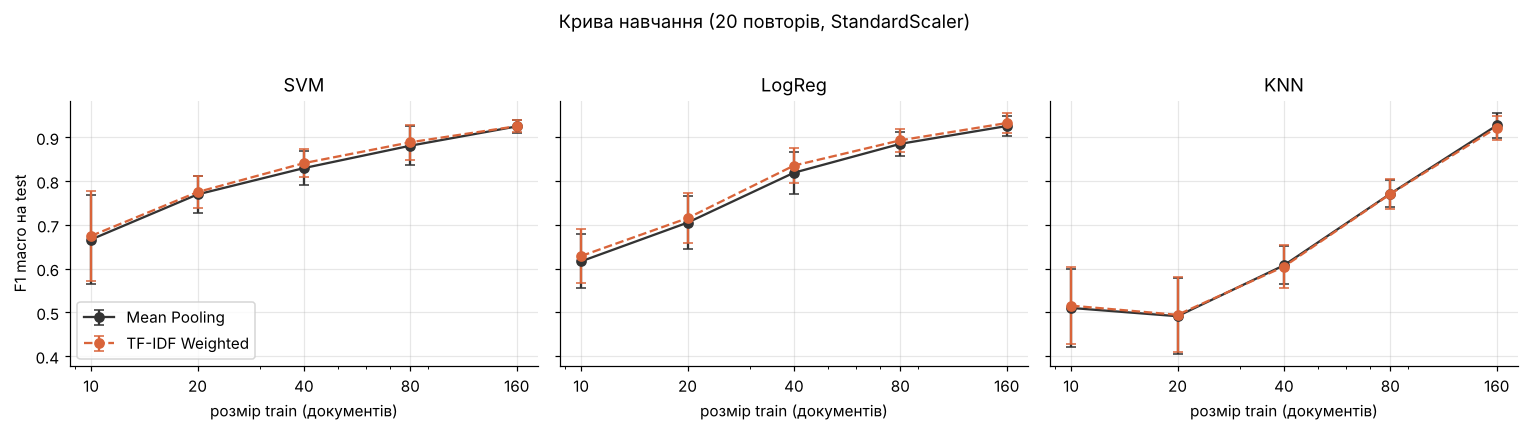

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, name in zip(ax, ['SVM', 'LogReg', 'KNN']):
    for agg, ls in [('Mean Pooling', '-'), ('TF-IDF Weighted', '--')]:
        g = lc[(lc.clf == name) & (lc.aggr == agg)].groupby('n').F1_macro
        a.errorbar(sizes, g.mean(), yerr=g.std(), ls=ls, marker='o', capsize=3, label=agg,
                   color='#333333' if agg == 'Mean Pooling' else '#D9643A')
    a.set(xscale='log', xticks=sizes, xticklabels=sizes, title=name, xlabel='розмір train (документів)')
ax[0].set_ylabel('F1 macro на test'); ax[0].legend()
plt.suptitle('Крива навчання (20 повторів, StandardScaler)', y=1.02); plt.tight_layout(); plt.show()

In [20]:
# Узагальнення на НОВІ шаблони: StratifiedGroupKFold за шаблоном
groups = df.tpl_id.values
rows = []
for rep in range(3):
    sgkf = StratifiedGroupKFold(5, shuffle=True, random_state=rep)
    for fold, (gtr, gte) in enumerate(sgkf.split(idx, y, groups)):
        Xm_g, Xt_g = build_features(tokens, gtr)
        for agg, Xa in {'Mean Pooling': Xm_g, 'TF-IDF Weighted': Xt_g}.items():
            for name, clf in make_classifiers().items():
                m, _ = evaluate(make_pipeline(StandardScaler(), clf), Xa[gtr], y[gtr], Xa[gte], y[gte])
                rows.append({'rep': rep, 'fold': fold, 'agg': agg, 'clf': name, **m})
grp = pd.DataFrame(rows)
grp.groupby(['clf', 'agg'])[['F1_macro', 'Balanced_Acc', 'ROC_AUC']].agg(['mean', 'std']).round(3)

F1_macro        Balanced_Acc        ROC_AUC       
                           mean    std         mean    std    mean    std
clf    agg                                                               
KNN    Mean Pooling       0.403  0.140        0.524  0.084   0.541  0.120
       TF-IDF Weighted    0.411  0.100        0.507  0.081   0.526  0.160
LogReg Mean Pooling       0.315  0.032        0.497  0.022   0.259  0.183
       TF-IDF Weighted    0.376  0.191        0.436  0.191   0.329  0.256
SVM    Mean Pooling       0.360  0.081        0.519  0.038   0.613  0.212
       TF-IDF Weighted    0.336  0.051        0.501  0.027   0.468  0.171

**На нових шаблонах усі моделі опускаються до рівня випадкового вгадування**: Balanced Accuracy ≈ 0.44–0.52,
F1 macro 0.31–0.41. ROC-AUC LogReg навіть систематично нижчий за 0.5 (0.26–0.33): ознаки, що розрізняли
класи на бачених шаблонах, на нових інвертуються. Це прямий доказ того, що 100 % з п. 5.1 означають
**впізнавання шаблону**, а не виявлення властивостей «штучного» тексту. Розкид між фолдами великий
(std до 0.19), бо в кожному тестовому фолді лише ~7 шаблонів.

---
# Етап 6. Візуалізація та аналіз

### 6.1 Проєкції t-SNE та UMAP

Вектори перед проєкцією стандартизовано. t-SNE: `perplexity=30`, ініціалізація PCA; UMAP: `n_neighbors=15, min_dist=0.1`.

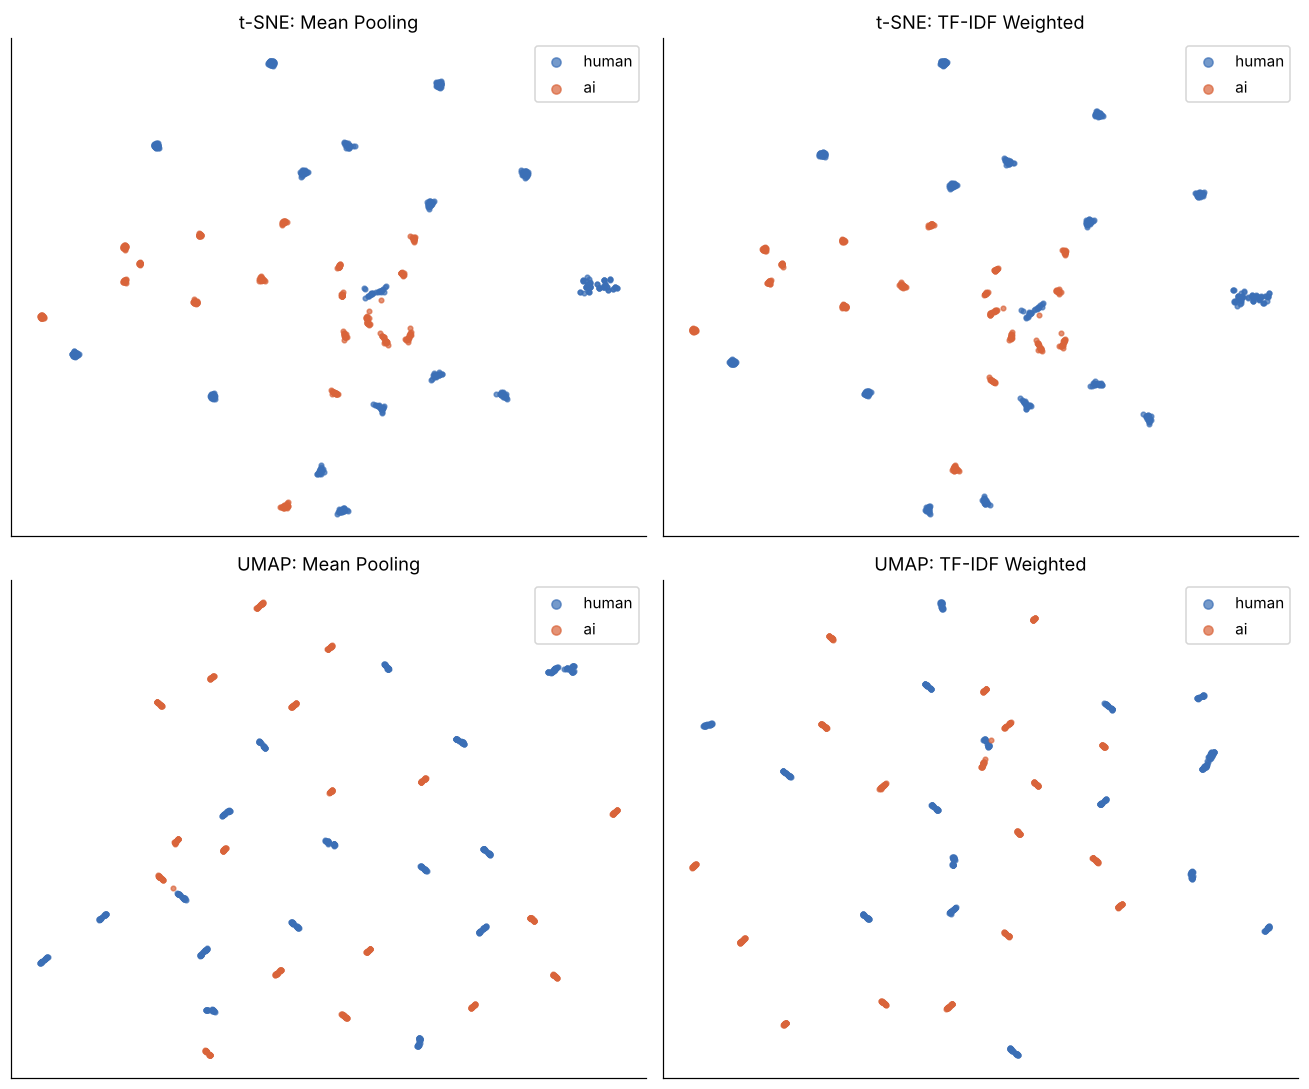

In [21]:
emb2d = {}
for agg, Xa in X.items():
    Z = StandardScaler().fit_transform(Xa)
    emb2d[(agg, 't-SNE')] = TSNE(n_components=2, perplexity=30, random_state=SEED, init='pca').fit_transform(Z)
    emb2d[(agg, 'UMAP')] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(Z)

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for r, method in enumerate(['t-SNE', 'UMAP']):
    for c, agg in enumerate(X):
        a = ax[r, c]; E = emb2d[(agg, method)]
        for lab, val in [('human', 0), ('ai', 1)]:
            msk = y == val
            a.scatter(E[msk, 0], E[msk, 1], s=9, alpha=.7, color=COL[lab], label=lab)
        a.set(title=f'{method}: {agg}', xticks=[], yticks=[]); a.grid(False)
        a.legend(markerscale=2, loc='best')
plt.tight_layout(); plt.show()

Обидва методи проєкції показують однакову картину: точки утворюють **≈ 34 маленьких щільних кластери**
(кількість шаблонів), кожен з яких містить тексти лише одного класу. Двох великих кластерів «AI» і «Human»
немає — кластери обох класів перемежовані. Найбільш «розмитий» кластер (human, новини) — шаблон
«Officials confirmed on *<day>* that…»: крім теми, у ньому змінюється ще й день тижня, тож тексти шаблону
відрізняються між собою сильніше, ніж в інших.

Проєкції Mean Pooling і TF-IDF Weighted майже ідентичні з точністю до повороту — що й очікувано,
враховуючи косинус ≈ 0.9998 між двома векторами одного документа (п. 6.3).

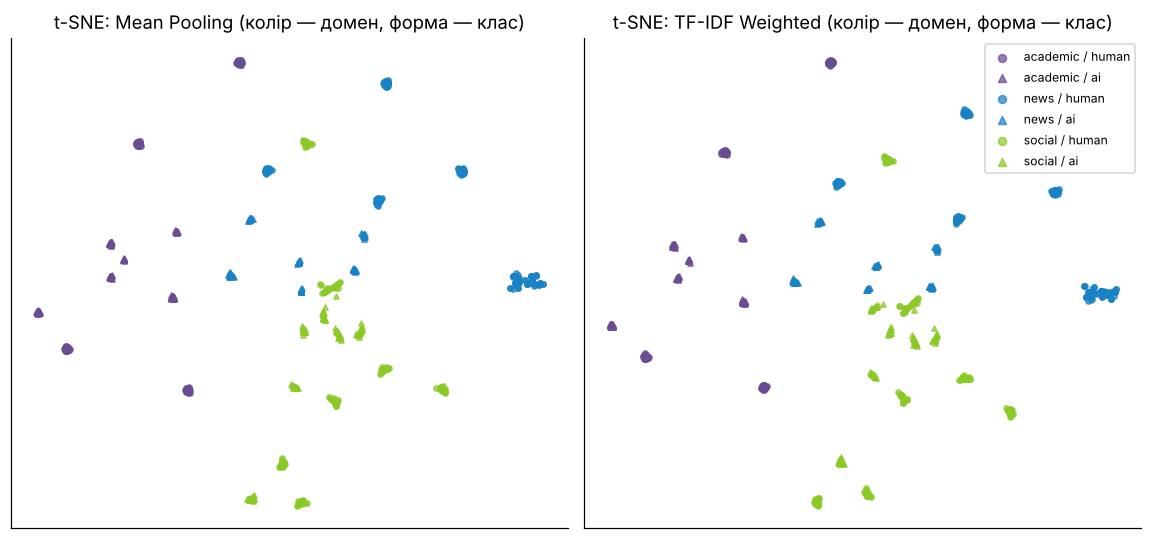

In [22]:
# Ті самі t-SNE, розфарбовані за доменом: що саме формує кластери
dom_col = {'academic': '#6A4C93', 'news': '#1982C4', 'social': '#8AC926'}
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, agg in zip(ax, X):
    E = emb2d[(agg, 't-SNE')]
    for dname, col in dom_col.items():
        for val, mk in [(0, 'o'), (1, '^')]:
            msk = (df.domain.values == dname) & (y == val)
            a.scatter(E[msk, 0], E[msk, 1], s=12, alpha=.7, color=col, marker=mk,
                      label=f'{dname} / {"ai" if val else "human"}')
    a.set(title=f't-SNE: {agg} (колір — домен, форма — клас)', xticks=[], yticks=[]); a.grid(False)
ax[1].legend(fontsize=8, markerscale=1.5, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

Глобальне розташування кластерів визначає **домен**: news, social та academic займають окремі області,
і всередині кожної області є кластери обох класів. Тобто головна вісь варіації ембедингів — тематика/жанр,
а клас — вторинна ознака, закодована в тому, *який саме* шаблон використано.

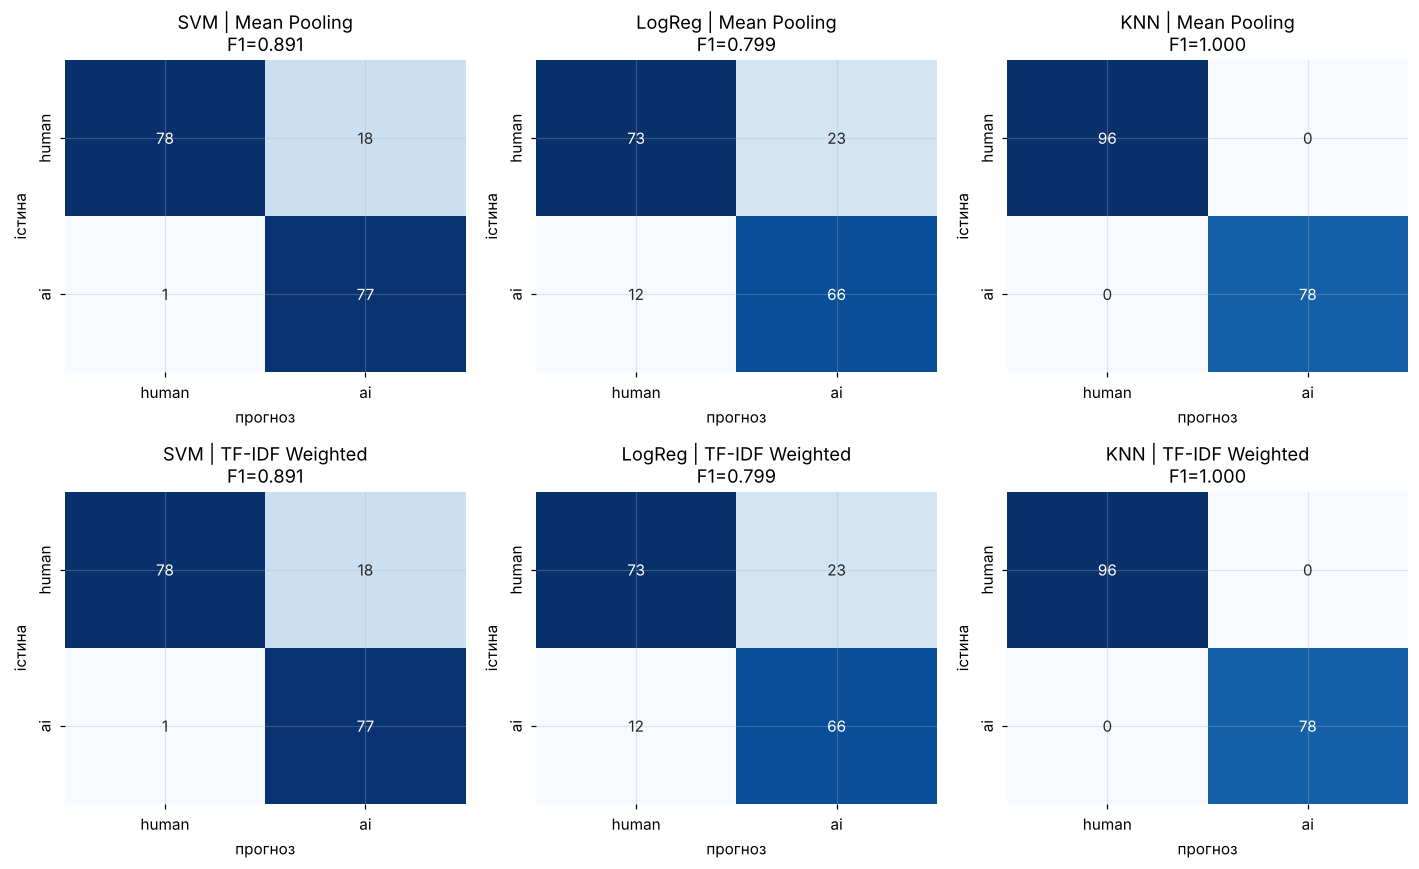

In [23]:
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for r, agg in enumerate(X):
    for c, name in enumerate(['SVM', 'LogReg', 'KNN']):
        cm = confusion_matrix(y_test, preds[(agg, name)])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[r, c],
                    xticklabels=['human', 'ai'], yticklabels=['human', 'ai'])
        f1 = res_main.loc[(name, agg), 'F1_macro']
        ax[r, c].set(title=f'{name} | {agg}\nF1={f1:.3f}', xlabel='прогноз', ylabel='істина')
plt.tight_layout(); plt.show()

### 6.2 Матриці плутанини

На тест-спліті KNN не помиляється. SVM без масштабування помиляється майже лише в один бік: **18 людських текстів
віднесено до AI** і лише 1 AI-текст — до human. LogReg помиляється в обидва боки (23 human → AI, 12 AI → human).
Тобто сильно регуляризовані моделі «стягують» частину людських шаблонів у бік AI-класу. Матриці для Mean і TF-IDF
**повністю збігаються**: на тест-спліті зважування не змінило жодного прогнозу.

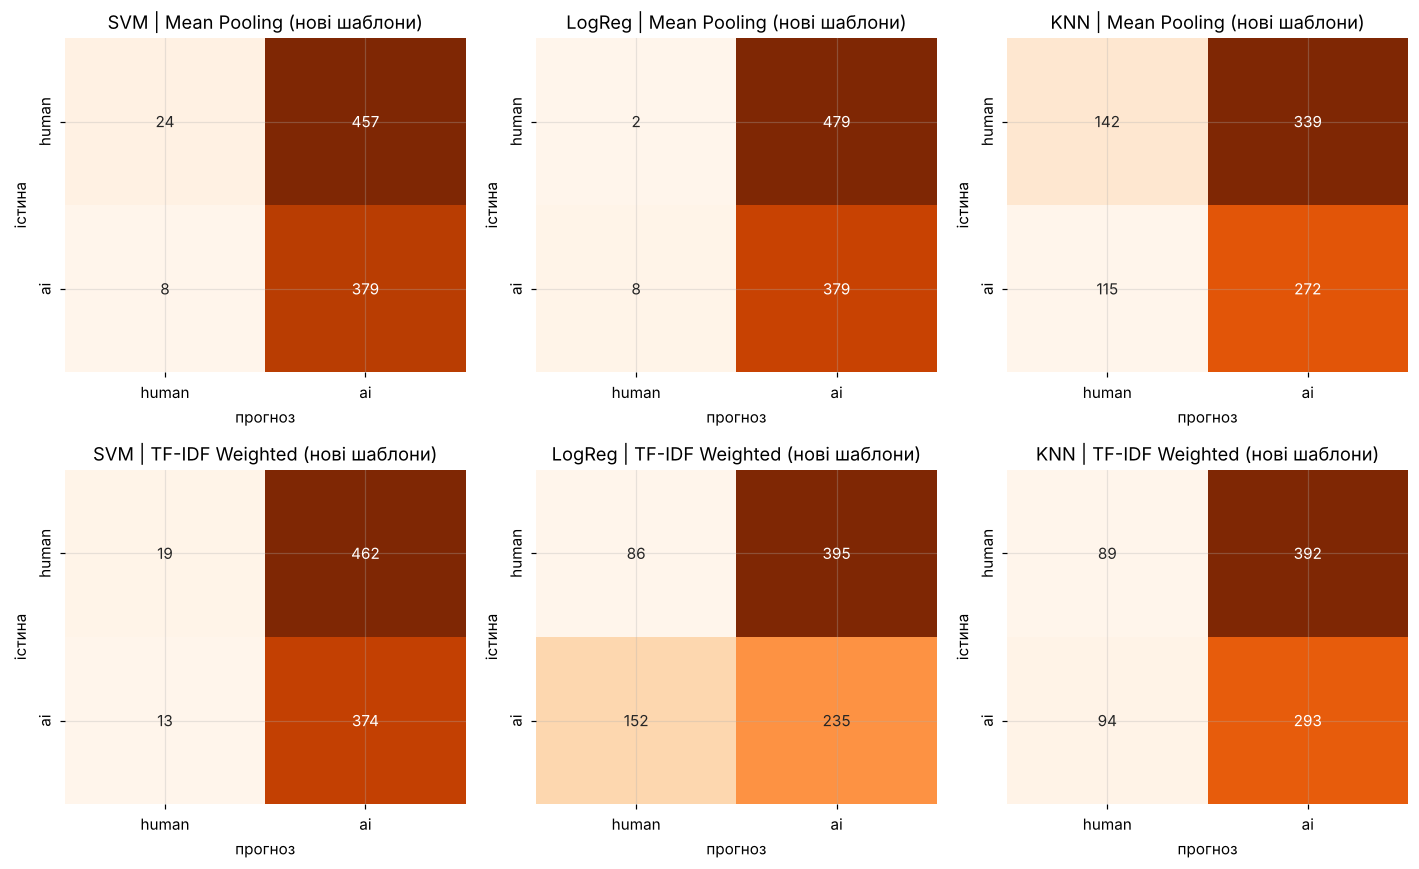

In [24]:
# Конфузійні матриці у сценарії «нові шаблони» (сумарно по 5 фолдах, rep=0)
cms = {k: np.zeros((2, 2), int) for k in [(a, n) for a in X for n in ['SVM', 'LogReg', 'KNN']]}
for gtr, gte in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(idx, y, groups):
    Xm_g, Xt_g = build_features(tokens, gtr)
    for agg, Xa in {'Mean Pooling': Xm_g, 'TF-IDF Weighted': Xt_g}.items():
        for name, clf in make_classifiers().items():
            mdl = make_pipeline(StandardScaler(), clf).fit(Xa[gtr], y[gtr])
            cms[(agg, name)] += confusion_matrix(y[gte], mdl.predict(Xa[gte]), labels=[0, 1])
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for r, agg in enumerate(X):
    for c, name in enumerate(['SVM', 'LogReg', 'KNN']):
        sns.heatmap(cms[(agg, name)], annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax[r, c],
                    xticklabels=['human', 'ai'], yticklabels=['human', 'ai'])
        ax[r, c].set(title=f'{name} | {agg} (нові шаблони)', xlabel='прогноз', ylabel='істина')
plt.tight_layout(); plt.show()

У сценарії «нові шаблони» картина інша: **SVM і LogReg відносять до AI майже всі тексти** незнайомих шаблонів
(87–100 % прогнозів «AI» у кожному фолді при реальній частці AI ≈ 0.45). Людські тексти нового шаблону для моделі
схожі на AI-клас більше, ніж на вивчені людські кластери. KNN поводиться нестабільно: залежно від фолду
«тягне» в один або інший клас. Звідси F1 macro ≈ 0.3–0.4 (майже вся вибірка в одному класі).

### 6.3 Геометричні властивості просторів

Кількісно порівняємо два простори (на стандартизованих векторах усіх 868 документів).

In [25]:
from sklearn.svm import LinearSVC
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import pdist

def geometry(Xa, y, k=5):
    Z = StandardScaler().fit_transform(Xa)
    mu0, mu1 = Z[y == 0].mean(0), Z[y == 1].mean(0)
    within = np.mean([Z[y == c].var(0).sum() for c in [0, 1]])
    nbr = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    D = pdist(Z)
    cos = 1 - pdist(Xa, 'cosine')
    pca = PCA().fit(Z); evr = pca.explained_variance_ratio_
    lin = LinearSVC(C=1.0, max_iter=20000).fit(Z, y)
    margin = 1 / np.linalg.norm(lin.coef_)
    return {
        'Середня косинусна схожість (анізотропія)': cos.mean(),
        'Відстань між центроїдами класів / √(внутрішньокл. дисперсія)': np.linalg.norm(mu0 - mu1) / np.sqrt(within),
        'Silhouette (евклід, стандарт.)': silhouette_score(Z, y),
        'Чистота 5-NN околу (частка сусідів свого класу)': (y[nbr] == y[:, None]).mean(),
        'Відносний контраст відстаней (max−min)/min': ((D.max() - D.min()) / D.min()),
        'CV попарних відстаней (std/mean)': D.std() / D.mean(),
        'Компонент PCA для 90% дисперсії': int(np.searchsorted(np.cumsum(evr), .9) + 1),
        'Частка дисперсії PC1': evr[0],
        'Лінійна відокремлюваність: точність LinearSVC на всіх даних': lin.score(Z, y),
        'Геометричний зазор LinearSVC 1/||w||': margin,
    }
geo = pd.DataFrame({agg: geometry(Xa, y) for agg, Xa in X.items()})
geo.round(4)

,Mean Pooling,TF-IDF Weighted
Середня косинусна схожість (анізотропія),0.8314,0.8337
Відстань між центроїдами класів / √(внутрішньокл. дисперсія),0.4272,0.4279
"Silhouette (евклід, стандарт.)",0.0609,0.0625
Чистота 5-NN околу (частка сусідів свого класу),0.9984,0.9986
Відносний контраст відстаней (max−min)/min,360.2557,293.1385
CV попарних відстаней (std/mean),0.3734,0.3712
Компонент PCA для 90% дисперсії,8.0000,8.0000
Частка дисперсії PC1,0.3381,0.3304
Лінійна відокремлюваність: точність LinearSVC на всіх даних,1.0000,1.0000
Геометричний зазор LinearSVC 1/||w||,0.2093,0.2283


Майже всі метрики для двох просторів збігаються до другого знака. Систематичні відмінності TF-IDF:

* **зазор LinearSVC зростає на ≈ 9 %** (0.209 → 0.228) — класи лінійно відокремлюються з більшим запасом;
* silhouette і відстань між центроїдами — мізерно більші;
* частка PC1 трохи менша (0.338 → 0.330), анізотропія практично та сама;
* **відносний контраст відстаней зменшився** (360 → 293), тобто відстані стали трохи більш «концентрованими».

Обидва простори сильно анізотропні: середній косинус між випадковими документами ≈ 0.83, 90 % дисперсії
вкладається у 8 компонент зі 100. Silhouette ≈ 0.06 (класи не є компактними хмарами) при 99.8 % чистоти 5-NN
околу — типова картина «багато маленьких чистих кластерів».

In [26]:
# Наскільки TF-IDF взагалі «зсуває» документні вектори
cos_same = np.sum(X_mean * X_tfidf, 1) / (np.linalg.norm(X_mean, axis=1) * np.linalg.norm(X_tfidf, axis=1))
print(f'Косинус між Mean- і TF-IDF-вектором ОДНОГО документа: середнє {cos_same.mean():.4f}, мінімум {cos_same.min():.4f}')

# Нерівномірність ваг усередині документа
cvw, maxw = [], []
for i in range(len(df)):
    d = M_tfidf[i].data
    if len(d) > 1:
        w = d / d.sum(); cvw.append(w.std() / w.mean()); maxw.append(w.max() * len(w))
print(f'Коефіцієнт варіації нормованих ваг у документі: {np.mean(cvw):.3f} (0 = рівні ваги, як у Mean)')
print(f'Найбільша вага відносно рівної 1/m: у середньому ×{np.mean(maxw):.2f}')
tf_counts = np.concatenate([np.unique(t, return_counts=True)[1] for t in df.tokens])
print(f'Частка лем, що трапляються в документі один раз (tf=1): {(tf_counts == 1).mean():.1%}')
print(f'Діапазон IDF у словнику: {tfidf.idf_.min():.2f} … {tfidf.idf_.max():.2f}')

# Перетин k-NN околів у двох просторах і «хабність»
k = 5
nn = {agg: NearestNeighbors(n_neighbors=k + 1).fit(StandardScaler().fit_transform(Xa))
             .kneighbors(StandardScaler().fit_transform(Xa), return_distance=False)[:, 1:]
      for agg, Xa in X.items()}
overlap = np.mean([len(set(a) & set(b)) / k for a, b in zip(nn['Mean Pooling'], nn['TF-IDF Weighted'])])
print(f'\nСередній перетин 5-NN околів документа у двох просторах: {overlap:.1%}')
from scipy.stats import skew
for agg in X:
    occ = np.bincount(nn[agg].ravel(), minlength=len(df))
    print(f'{agg:>16}: асиметрія k-occurrence (хабність) = {skew(occ):.2f}, '
          f'документів, що не є нічиїм сусідом: {(occ == 0).mean():.1%}')

Косинус між Mean- і TF-IDF-вектором ОДНОГО документа: середнє 0.9998, мінімум 0.9969
Коефіцієнт варіації нормованих ваг у документі: 0.148 (0 = рівні ваги, як у Mean)
Найбільша вага відносно рівної 1/m: у середньому ×1.25
Частка лем, що трапляються в документі один раз (tf=1): 99.2%
Діапазон IDF у словнику: 2.49 … 6.85

Середній перетин 5-NN околів документа у двох просторах: 89.6%
    Mean Pooling: асиметрія k-occurrence (хабність) = 0.54, документів, що не є нічиїм сусідом: 10.8%
 TF-IDF Weighted: асиметрія k-occurrence (хабність) = 0.41, документів, що не є нічиїм сусідом: 11.1%


Головна причина слабкого ефекту: **TF-IDF вектор документа майже збігається з Mean-вектором**
(косинус 0.9998, мінімум 0.997). 99 % лем мають tf = 1, IDF після згладжування лежить у вузькому діапазоні
2.5–6.9, тому ваги всередині документа відхиляються від рівних лише на ~15 % (коефіцієнт варіації 0.148),
а найбільша вага в середньому лише в 1.25 раза більша за рівну. Проте k-NN околи змінюються помітніше
за самі вектори: у середньому лише ~90 % п'яти найближчих сусідів спільні для двох просторів.

In [27]:
# Внесок окремих слів: які терміни «тягнуть» документ у TF-IDF vs Mean
# Порівняння середньої ваги токена в документі за двох схем
rows = []
idf = dict(zip(tfidf.get_feature_names_out(), tfidf.idf_))
for doc in df.tokens[tr_idx]:
    known = [t for t in doc if t in idf]
    if not known: continue
    s = pd.Series([idf[t] for t in known]); s = s / s.sum()
    for t, wv in zip(known, s): rows.append((t, wv, 1 / len(known)))
wt = pd.DataFrame(rows, columns=['token', 'w_tfidf', 'w_mean']).groupby('token').mean()
wt['ratio'] = wt.w_tfidf / wt.w_mean
docfreq = pd.Series({t: sum(t in set(d) for d in df.tokens[tr_idx]) for t in wt.index})
wt['df'] = docfreq
print('Найбільш посилені TF-IDF (рідкісні):'); print(wt.sort_values('ratio', ascending=False).head(8).round(3))
print('\nНайбільш послаблені (часті):'); print(wt.sort_values('ratio').head(8).round(3))

Найбільш посилені TF-IDF (рідкісні):
           w_tfidf  w_mean  ratio  df
token                                
data         0.086   0.048  1.813   1
media        0.149   0.091  1.638   1
thursday     0.073   0.047  1.567   5
break        0.066   0.045  1.484   3
monday       0.070   0.047  1.477   8
wednesday    0.069   0.048  1.444   9
hiring       0.054   0.037  1.443   4
tuesday      0.066   0.047  1.402  11

Найбільш послаблені (часті):
           w_tfidf  w_mean  ratio   df
token                                 
challenge    0.027   0.043  0.624  156
study        0.025   0.035  0.710  114
finding      0.026   0.035  0.745  100
official     0.033   0.044  0.748  110
datum        0.029   0.038  0.749   99
research     0.040   0.054  0.752   87
come         0.045   0.060  0.753  102
new          0.031   0.041  0.756   91


Що саме посилює TF-IDF: найбільше зростають ваги **назв днів тижня** (`monday`, `thursday`…, ×1.4–1.6) та
слів, що трапились у 1–3 документах. Дні тижня — це змінна частина людського шаблону «Officials confirmed on *<day>*…»:
вони рідкісні, але **не несуть інформації про клас** — це шум, який TF-IDF підсилює
(саме цей шаблон утворює найбільш розмитий кластер на t-SNE).
Найбільше послаблюються часті слова `challenge`, `study`, `finding`, `research`, які є в обох класах —
саме ті, що за гіпотезою «розмивають» Mean Pooling.

### 6.4 Лінгвістичний аналіз: слова та n-грами з найбільшим TF-IDF для класу AI

Рахуємо середнє TF-IDF кожної леми окремо по AI- та Human-документах train і різницю між ними.
Для n-грам — окремий `TfidfVectorizer(ngram_range=(2, 3), min_df=3)` на лематизованому тексті.

In [28]:
train_df = df.iloc[tr_idx]
tf_uni = TfidfVectorizer(analyzer=lambda x: x).fit(train_df.tokens)
tf_bi = TfidfVectorizer(tokenizer=str.split, lowercase=False, preprocessor=None, token_pattern=None,
                        ngram_range=(2, 3), min_df=3).fit(train_df.tokens.str.join(' '))

def class_tfidf(vec, docs, labels, top=15):
    M = vec.transform(docs)
    names = vec.get_feature_names_out()
    ai = np.asarray(M[labels == 1].mean(0)).ravel()
    hu = np.asarray(M[labels == 0].mean(0)).ravel()
    pres_ai = np.asarray((M[labels == 1] > 0).mean(0)).ravel()
    pres_hu = np.asarray((M[labels == 0] > 0).mean(0)).ravel()
    t = pd.DataFrame({'mean_tfidf_AI': ai, 'mean_tfidf_Human': hu, 'diff': ai - hu,
                      'docs_AI_%': pres_ai * 100, 'docs_Human_%': pres_hu * 100}, index=names)
    return t

yt = y[tr_idx]
uni = class_tfidf(tf_uni, train_df.tokens, yt)
print('Топ-15 лем за середнім TF-IDF у класі AI:')
display(uni.sort_values('mean_tfidf_AI', ascending=False).head(15).round(3))
print('Топ-15 лем, найбільш специфічних для AI (різниця середніх TF-IDF AI − Human):')
display(uni.sort_values('diff', ascending=False).head(15).round(3))

Топ-15 лем за середнім TF-IDF у класі AI:


,mean_tfidf_AI,mean_tfidf_Human,diff,docs_AI_%,docs_Human_%
challenge,0.039,0.023,0.016,29.450,16.883
framework,0.037,0.008,0.028,18.123,5.714
think,0.035,0.000,0.035,6.796,0.000
conversation,0.032,0.014,0.017,16.828,6.494
underscore,0.030,0.000,0.030,18.770,0.000
development,0.029,0.000,0.029,17.476,0.000
point,0.029,0.012,0.017,16.181,5.455
expert,0.029,0.000,0.029,16.181,0.000
research,0.029,0.016,0.013,19.417,7.013
datum,0.028,0.015,0.013,19.417,10.130


Топ-15 лем, найбільш специфічних для AI (різниця середніх TF-IDF AI − Human):


,mean_tfidf_AI,mean_tfidf_Human,diff,docs_AI_%,docs_Human_%
think,0.035,0.000,0.035,6.796,0.000
underscore,0.030,0.000,0.030,18.770,0.000
development,0.029,0.000,0.029,17.476,0.000
expert,0.029,0.000,0.029,16.181,0.000
framework,0.037,0.008,0.028,18.123,5.714
solution,0.027,0.000,0.027,14.887,0.000
stakeholder,0.027,0.000,0.027,15.534,0.000
potential,0.027,0.000,0.027,11.650,0.000
recommendation,0.026,0.000,0.026,15.858,0.000
open,0.025,0.000,0.025,12.298,0.000


Найбільші **абсолютні** значення TF-IDF в AI мають `challenge`, `framework`, `conversation`, `research`, `study` —
але ці слова частково є і в людських текстах. Найбільш **специфічні** для AI (трапляються лише в AI) —
`underscore`, `stakeholder`, `framework`, `solution`, `recommendation`, `potential`, `address`, `methodological`,
`development`, `expert`, `think`.

In [29]:
bi = class_tfidf(tf_bi, train_df.tokens.str.join(' '), yt)
print('Топ-15 біграм/триграм лем, специфічних для AI:')
display(bi.sort_values('diff', ascending=False).head(15).round(3))
print('Топ-10 n-грам, специфічних для Human:')
display(bi.sort_values('diff').head(10).round(3))

Топ-15 біграм/триграм лем, специфічних для AI:


,mean_tfidf_AI,mean_tfidf_Human,diff,docs_AI_%,docs_Human_%
approach thoughtfully thought,0.017,0.0,0.017,6.149,0.0
approach thoughtfully,0.017,0.0,0.017,6.149,0.0
thing move,0.017,0.0,0.017,6.149,0.0
thoughtfully thought,0.017,0.0,0.017,6.149,0.0
potential approach,0.017,0.0,0.017,6.149,0.0
fascinating quickly thing,0.017,0.0,0.017,6.149,0.0
quickly thing move,0.017,0.0,0.017,6.149,0.0
potential approach thoughtfully,0.017,0.0,0.017,6.149,0.0
fascinating quickly,0.017,0.0,0.017,6.149,0.0
quickly thing,0.017,0.0,0.017,6.149,0.0


Топ-10 n-грам, специфічних для Human:


,mean_tfidf_AI,mean_tfidf_Human,diff,docs_AI_%,docs_Human_%
announcement come week,0.0,0.019,-0.019,0.0,12.208
week speculation critic,0.0,0.019,-0.019,0.0,12.208
announcement come,0.0,0.019,-0.019,0.0,12.208
long overdue public,0.0,0.019,-0.019,0.0,12.208
public response,0.0,0.019,-0.019,0.0,12.208
public response divide,0.0,0.019,-0.019,0.0,12.208
supporter long,0.0,0.019,-0.019,0.0,12.208
supporter long overdue,0.0,0.019,-0.019,0.0,12.208
overdue public,0.0,0.019,-0.019,0.0,12.208
overdue public response,0.0,0.019,-0.019,0.0,12.208


Серед n-грам AI: *approach thoughtfully*, *nuanced conversation … polarization*, *need nuanced*, *think lot*,
*fascinating quickly thing move* («Really fascinating to see how quickly things are moving…»).
Серед людських: *critic argue premature*, *long overdue*, *public response divide predictable line*.

In [30]:
# Контроль: чи працюють ці маркери на текстах із НОВИХ шаблонів?
# Логістична регресія на TF-IDF мішку слів, перевірена за групами-шаблонами
from sklearn.model_selection import cross_val_score
bow_pipe = make_pipeline(TfidfVectorizer(analyzer=lambda x: x), LogisticRegression(max_iter=2000))
docs_all = np.array(df.tokens.tolist(), dtype=object)
s_rand = cross_val_score(bow_pipe, docs_all, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='f1_macro')
s_grp = cross_val_score(bow_pipe, docs_all, y, cv=StratifiedGroupKFold(5, shuffle=True, random_state=0), groups=groups, scoring='f1_macro')
print(f'TF-IDF BoW + LogReg | випадковий спліт: F1={s_rand.mean():.3f}  | нові шаблони: F1={s_grp.mean():.3f}')

TF-IDF BoW + LogReg | випадковий спліт: F1=1.000  | нові шаблони: F1=0.319


Контроль: навіть прямий класифікатор на мішку TF-IDF слів має F1 = 1.0 на випадковому спліті й лише 0.32 на нових
шаблонах — ці слова не переносяться на тексти іншої структури.

In [31]:
# Як «маркерні» слова розподілені по шаблонах AI
for w in uni.sort_values('diff', ascending=False).head(6).index:
    has = df.tokens.apply(lambda d: w in d)
    print(f'{w:>14}: у {has[y==1].mean():5.1%} AI-текстів, {has[y==0].mean():5.1%} Human; '
          f'шаблонів AI з цим словом: {df[has & (y==1)].template.nunique()}')

         think: у  6.7% AI-текстів,  0.0% Human; шаблонів AI з цим словом: 1
    underscore: у 17.1% AI-текстів,  0.0% Human; шаблонів AI з цим словом: 3
   development: у 17.1% AI-текстів,  0.0% Human; шаблонів AI з цим словом: 3
        expert: у 16.5% AI-текстів,  0.0% Human; шаблонів AI з цим словом: 3
     framework: у 17.1% AI-текстів,  6.0% Human; шаблонів AI з цим словом: 3
      solution: у 15.5% AI-текстів,  0.0% Human; шаблонів AI з цим словом: 3


Кожне «маркерне» слово трапляється лише в 1–3 AI-шаблонах із 18. Тобто це не розподілена властивість AI-класу,
а фрагменти конкретних шаблонних речень.

FINAL

In [32]:
from scipy.stats import wilcoxon
def paired(dfr, key, metric='F1_macro'):
    out = []
    for name in ['SVM', 'LogReg', 'KNN']:
        p = dfr[dfr.clf == name].pivot_table(index=key, columns=dfr.columns[dfr.columns.isin(['agg', 'aggr'])][0], values=metric)
        d = p['TF-IDF Weighted'] - p['Mean Pooling']
        out.append({'Класифікатор': name, 'Δ F1 (TF-IDF − Mean)': d.mean(),
                    'TF-IDF краще, %': (d > 0).mean() * 100, 'TF-IDF гірше, %': (d < 0).mean() * 100,
                    'p (Wilcoxon)': wilcoxon(d).pvalue if (d != 0).any() else 1.0})
    return pd.DataFrame(out).set_index('Класифікатор').round(4)
print('Крива навчання (усі n і повтори, парно):'); display(paired(lc, ['n', 'rep']))
print('Нові шаблони (15 фолдів, парно):'); display(paired(grp, ['rep', 'fold']))

Крива навчання (усі n і повтори, парно):


,Δ F1 (TF-IDF − Mean),"TF-IDF краще, %","TF-IDF гірше, %",p (Wilcoxon)
Класифікатор,,,,
SVM,0.0067,51.0,17.0,0.0000
LogReg,0.0107,62.0,18.0,0.0000
KNN,-0.0001,36.0,47.0,0.7766


Нові шаблони (15 фолдів, парно):


,Δ F1 (TF-IDF − Mean),"TF-IDF краще, %","TF-IDF гірше, %",p (Wilcoxon)
Класифікатор,,,,
SVM,-0.0241,26.6667,26.6667,0.5754
LogReg,0.0607,60.0000,40.0000,0.2293
KNN,0.0082,66.6667,33.3333,0.7615


**Значущість ефекту TF-IDF.** На кривій навчання (100 парних порівнянь: 5 розмірів × 20 повторів)
TF-IDF дає невелике, але **статистично значуще** покращення для SVM (+0.7 п.п., p < 0.001) і LogReg
(+1.1 п.п., p < 0.001; TF-IDF краще в 62 % пар і гірше лише в 18 %). Для KNN ефекту немає
(Δ ≈ 0, p = 0.78; гірше в 47 % пар, краще в 36 %). На нових шаблонах різниці незначущі (p > 0.2) — на рівні
випадкового вгадування порівнювати агрегації немає сенсу.

In [33]:
# Варіант із ваговою схемою точно за формулою (4): idf = ln(|D| / df), без згладжування «+1»
N_tr = len(tr_idx)
df_cnt = pd.Series([t for i in tr_idx for t in set(tokens[i])]).value_counts()
idf_pure = np.log(N_tr / df_cnt)

def build_pure(tokens, train_idx, model):
    n = len(train_idx)
    dfc = pd.Series([t for i in train_idx for t in set(tokens[i])]).value_counts()
    idf = np.log(n / dfc).to_dict()
    out = []
    for doc in tokens:
        cnt = pd.Series(doc).value_counts()
        sc = {t: (c / len(doc)) * idf[t] for t, c in cnt.items() if t in idf and idf[t] > 0}
        out.append(tfidf_weighted_pooling(doc, model, sc))
    return np.vstack(out)

X_pure = build_pure(tokens, tr_idx, ft)
cvw_p = []
for doc in tokens:
    w = np.array([idf_pure.get(t, 0) for t in doc]); w = w[w > 0]
    if len(w) > 1: w = w / w.sum(); cvw_p.append(w.std() / w.mean())
cos_p = np.sum(X_mean * X_pure, 1) / (np.linalg.norm(X_mean, axis=1) * np.linalg.norm(X_pure, axis=1))
print(f'IDF за формулою (4): діапазон {idf_pure.min():.2f} … {idf_pure.max():.2f}; '
      f'CV ваг у документі {np.mean(cvw_p):.3f}; косинус з Mean {cos_p.mean():.4f} (мін {cos_p.min():.4f})')
rows = []
for name, clf in make_classifiers().items():
    m, _ = evaluate(clf, X_pure[tr_idx], y_train, X_pure[te_idx], y_test)
    rows.append({'Класифікатор': name, 'Протокол': 'test-спліт (як у завданні)', 'F1': m['F1_macro']})
    for n in [20, 40, 80]:
        f = []
        for rep in range(20):
            sub, _ = train_test_split(tr_idx, train_size=n, stratify=y_train, random_state=rep)
            f.append(evaluate(make_pipeline(StandardScaler(), make_classifiers()[name]), X_pure[sub], y[sub], X_pure[te_idx], y_test)[0]['F1_macro'])
        rows.append({'Класифікатор': name, 'Протокол': f'крива навчання, n={n}', 'F1': np.mean(f)})
f = {k: [] for k in make_classifiers()}
for rep in range(3):
    for gtr, gte in StratifiedGroupKFold(5, shuffle=True, random_state=rep).split(idx, y, groups):
        ft_g = FastText(sentences=[tokens[i] for i in gtr], vector_size=100, window=5, min_count=2,
                        sg=1, workers=1, seed=SEED, hashfxn=stable_hash)
        Xp = build_pure(tokens, gtr, ft_g)
        for name, clf in make_classifiers().items():
            f[name].append(evaluate(make_pipeline(StandardScaler(), clf), Xp[gtr], y[gtr], Xp[gte], y[gte])[0]['F1_macro'])
for name in f:
    rows.append({'Класифікатор': name, 'Протокол': 'нові шаблони (15 фолдів)', 'F1': np.mean(f[name])})
pure_tab = pd.DataFrame(rows).pivot(index='Протокол', columns='Класифікатор', values='F1').round(3)
pure_tab

IDF за формулою (4): діапазон 1.49 … 6.54; CV ваг у документі 0.187; косинус з Mean 0.9996 (мін 0.9967)


Класифікатор,KNN,LogReg,SVM
Протокол,,,
test-спліт (як у завданні),1.000,0.804,0.885
"крива навчання, n=20",0.493,0.719,0.778
"крива навчання, n=40",0.604,0.841,0.841
"крива навчання, n=80",0.769,0.895,0.889
нові шаблони (15 фолдів),0.430,0.382,0.336


**TF-IDF точно за формулою (4)** (без «+1»): діапазон IDF ширший (1.5–6.5), ваги в документі нерівномірніші
(CV 0.187 проти 0.148), але вектор усе одно майже збігається з Mean (косинус 0.9996). Результати практично
такі самі, як у sklearn-варіанті: невелика перевага для LogReg на малих вибірках (n = 40: 0.841), нуль для KNN,
випадкове вгадування на нових шаблонах. Отже, висновки не залежать від конкретної формули IDF.

---
# Відповіді на дослідницькі питання

### 1. Вплив агрегації: як TF-IDF змінює геометрію простору і чи покращує лінійну роздільність?

TF-IDF замінює рівні ваги $1/m$ у сумі векторів слів (формула 5) на ваги, пропорційні IDF (формула 6).
Геометрично це **зсуває документний вектор у бік векторів рідкісних слів** і віддаляє його від «спільного центру»,
який формують часті слова (`challenge`, `study`, `research`, `finding`), що є в обох класах.
Якщо рідкісні слова специфічні для класу, центроїди класів розходяться і лінійна роздільність зростає —
у цьому й полягає гіпотеза.

На цьому датасеті механізм працює **у правильному напрямку, але з дуже малою амплітудою**:

* зазор лінійного SVM зростає на ≈ 9 % (0.209 → 0.228), silhouette і відстань між центроїдами — трохи;
* на малих вибірках LogReg і SVM з TF-IDF стабільно кращі (+1.1 і +0.7 п.п. F1, p < 0.001);
* на повних даних різниця зникає через ефект стелі — класи лінійно роздільні вже при Mean Pooling (LinearSVC = 100 %).

Причина малої амплітуди — **короткі тексти**: 99 % лем мають tf = 1, IDF коливається у вузькому діапазоні,
тож ваги відрізняються від рівних лише на ~15 %, а косинус між Mean- та TF-IDF-вектором одного документа 0.9998.
TF-IDF не може суттєво змінити геометрію, якщо ваги майже однакові. До того ж зважування підсилює не тільки
корисні рідкісні слова, а й шумові (назви днів тижня). Гіпотеза **частково підтверджена**: TF-IDF покращує лінійну
роздільність, але ефект практично помітний лише в режимі малої кількості даних.

### 2. Порівняння класифікаторів: хто кращий і як це пов'язано з природою даних?

| Сценарій | Найкращий | Пояснення |
|---|---|---|
| Повні дані, параметри з завдання | **KNN** (1.000 для обох агрегацій) | кожен шаблон — щільний чистий кластер, найближчий сусід завжди з того самого шаблону |
| Повні дані, зі StandardScaler | усі ≈ 0.98–1.00 | ефект стелі |
| Мало даних (10–80 документів) | **SVM / LogReg**, з TF-IDF | лінійна межа узагальнює краще, ніж пам'ять про приклади |
| Нові шаблони | ніхто (≈ випадково) | ознаки — ідентифікатори шаблонів; лінійні моделі майже все відносять до AI |

Дані **лінійно роздільні**, але **мультимодальні**: кожен клас — об'єднання 16–18 віддалених одне від одного
мікрокластерів. Для такої структури локальний метод (KNN) ідеальний, доки в train є приклади кожного шаблону,
а RBF-SVM поєднує обидві властивості. Слабкий результат LogReg «за замовчуванням» (0.80) — це не нелінійність
даних, а масштаб ознак і регуляризація `C=1`: після стандартизації або при `C=1000` LogReg теж дає ≈ 1.0.
Коли даних мало, KNN найгірший: він «бачить» лише ті шаблони, які випадково потрапили в train.

### 3. Чутливість KNN: чому KNN може деградувати при переході до TF-IDF?

KNN не навчає ваг ознак: рішення повністю визначається евклідовою метрикою на всіх 100 вимірах.
TF-IDF змінює саму метрику — зсуває вектори в напрямках рідкісних слів, незалежно від того, чи пов'язані ці
напрямки з класом. Лінійні моделі можуть занулити неінформативні напрямки ваговим вектором $w$, а KNN — ні:
шум, внесений підсиленням рідкісних слів (у нас це, наприклад, дні тижня й одиничні теми), безпосередньо
змінює ранжування сусідів.

Це посилюється **прокляттям розмірності**: у високорозмірному просторі відстані концентруються — найближчий
і найдальший сусід стають майже рівновіддаленими, і невеликий зсув векторів міняє склад околу.
У наших даних TF-IDF зменшив відносний контраст відстаней (360 → 293), а склад 5-NN околів змінився приблизно на 10 %.
Додатково анізотропія (середній косинус ≈ 0.83, 90 % дисперсії у 8 компонентах) означає, що «ефективна» розмірність
мала, а решта ~90 вимірів переважно шумові — і саме по них сумується евклідова відстань.

Експериментально: KNN — **єдиний класифікатор, якому TF-IDF не дає жодної користі** (Δ F1 ≈ 0, p = 0.78 на кривій
навчання, гірше в 47 % пар проти 36 % кращих), тоді як лінійні моделі значуще виграють. Сильної деградації ми не
спостерігаємо, бо ваги майже рівні й вектори змінюються ледь-ледь; на повних даних KNN тримається на 100 % завдяки
чистим кластерам шаблонів. На довших текстах із ширшим розкидом TF-IDF ваг слід очікувати сильнішого ефекту.

### 4. Лінгвістична інтерпретація: які слова мають найбільші TF-IDF для AI? Чи це маркери штучного тексту?

Найбільш специфічні для AI леми: `underscore`, `stakeholder`, `framework`, `solution`, `recommendation`,
`potential`, `address`, `methodological`, `development`, `expert`; n-грами: *approach thoughtfully*,
*nuanced conversation … polarization*, *acknowledge complexity*, *fascinating … quickly … move*.

Зовні це дуже схоже на відомий «стиль LLM»: канцеляризми (*underscore*, *stakeholders*, *address the challenge*),
обережні формулювання (*nuanced*, *acknowledge complexity*, *approach thoughtfully*), штучний ентузіазм (*fascinating*).
Саме таку лексику описує гіпотеза роботи.

Але як **загальні** маркери їх інтерпретувати не можна:

* кожне слово трапляється лише в 1–3 із 18 AI-шаблонів (у 6–19 % AI-текстів) — це частини конкретних речень, а не
  розподілена властивість класу;
* класифікатор на цих же TF-IDF ознаках має F1 = 1.0 на бачених шаблонах і 0.32 на нових.

Отже, на цьому датасеті ці слова — **маркери шаблонів**, які лише стилістично нагадують LLM-текст.
Для висновку про справжні маркери потрібні тексти, згенеровані LLM без фіксованих шаблонів, і перевірка на
незалежних джерелах.

### 5. Геометричний аналіз: чи утворюють класи компактні кластери на t-SNE і яка агрегація краща?

Класи **не утворюють** двох компактних кластерів. На t-SNE та UMAP видно ~34 маленьких щільних кластери —
по одному на шаблон, кожен однорідний за класом. Кластери AI та Human перемежовані, а глобальне розташування
задає домен (news / social / academic). Кількісно: silhouette за класом лише ≈ 0.06, тоді як 99.8 % п'яти
найближчих сусідів кожного документа належать до його класу.

Mean Pooling і TF-IDF дають візуально майже ідентичні проєкції. За метриками TF-IDF кластеризує трохи краще
(вищі silhouette і зазор, нижча частка PC1), але різниця на рівні тисячних — на графіках її не видно.

---
# Висновки

1. Реалізовано пайплайн spaCy → FastText → Mean / TF-IDF Weighted pooling → SVM / LogReg / KNN, усі статистики
   навчаються лише на train. Окремо зроблено код детермінованим (`workers=1`, стабільна хеш-функція), щоб результати
   відтворювались між запусками.
2. Датасет має суттєві артефакти: 52 % рядків — дублікати, ще 98 текстів збігаються після нормалізації; метадані
   `source_model` / `generation_method` видають мітку; тексти згенеровано з 34 шаблонів, жоден з яких не є спільним
   для класів. Без дедуплікації метрики були б завищені за рахунок тексту, що повторюється в train і test.
3. На випадковому спліті класифікація тривіальна (KNN = 1.0; після масштабування всі моделі ≈ 1.0), але на нових
   шаблонах усі моделі опускаються до рівня вгадування. Висока точність означає **впізнавання шаблону**, а не
   детекцію AI-тексту.
4. TF-IDF зважування дає невелике статистично значуще покращення для лінійних класифікаторів у режимі малої кількості
   даних (+0.7…1.1 п.п. F1) і збільшує зазор лінійного SVM на ≈ 9 %; для KNN користі немає. Ефект малий, бо в коротких
   текстах ваги TF-IDF майже рівні (вектори збігаються з косинусом 0.9998).
5. Для LogReg і RBF-SVM масштабування ознак важливіше за вибір агрегації: `StandardScaler` підвищує F1 LogReg з 0.82 до 0.99.

**Обмеження та що варто зробити далі:** повторити експеримент на датасеті з довшими текстами без шаблонів
(де TF-IDF ваги мають більший розкид); оцінювати модель на текстах невідомих генераторів / шаблонів;
не відкидати пунктуацію та регістр при препроцесингу — саме в них була людська варіативність цього датасету.